In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = sns.load_dataset('penguins')
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [6]:
df.isna().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


In [9]:
df.fillna(df.mode(), inplace=True)

In [10]:
df.columns

Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex'],
      dtype='object')

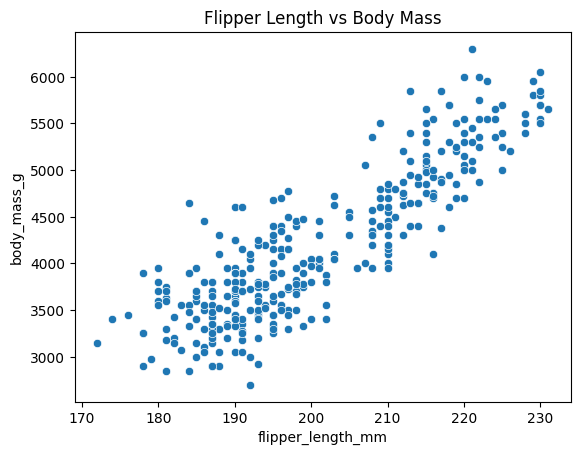

In [17]:
#scatter plot (how does flipper length scale with body mass)
sns.scatterplot(data= df, x = 'flipper_length_mm', y = 'body_mass_g')
plt.title('Flipper Length vs Body Mass')
plt.show()

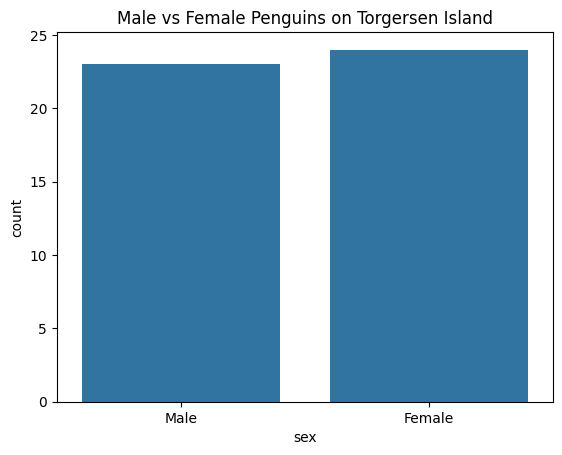

In [16]:
#bar chart (males vs females on torgersen)
torgersen_df = df[df['island'] == 'Torgersen']
sns.countplot(data=torgersen_df, x='sex')
plt.title('Male vs Female Penguins on Torgersen Island')
plt.show()

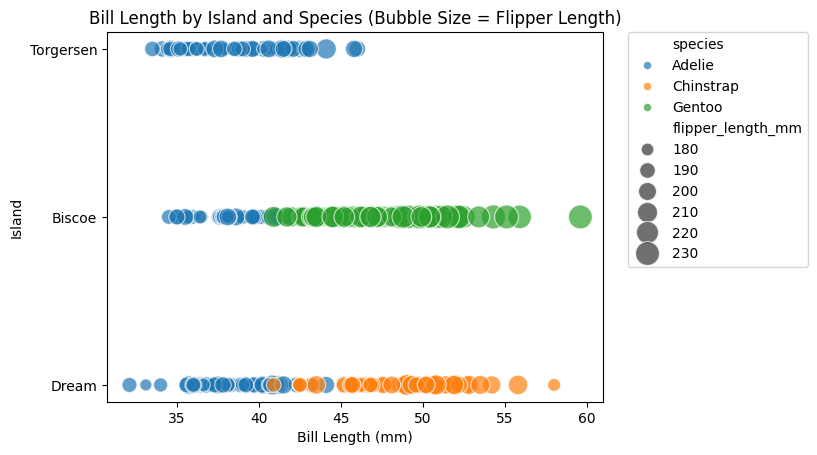

In [22]:
#bubble chart (species, bill length, island)
sns.scatterplot(
    data=df,
    x='bill_length_mm',
    y='island',
    hue='species',
    size='flipper_length_mm',
    sizes=(50, 300),
    alpha=0.7
)

plt.title("Bill Length by Island and Species (Bubble Size = Flipper Length)")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Island")
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)  # Put legend outside plot
plt.show()

Text(0.5, 1.0, 'Bill Length vs Bill Depth by Gender')

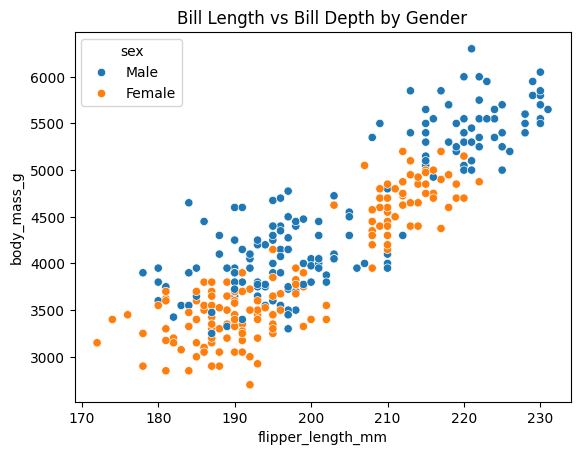

In [24]:
#color plot ( bill length vs bill depth by gender)

sns.scatterplot(data = df, x = "flipper_length_mm", y = "body_mass_g", hue = "sex")
plt.title("Bill Length vs Bill Depth by Gender")

Color plot was most effective for this dataset.

Bubble plot is very crowded and doesn't look "natural" like a scatter plot is supposed to

Scatter plot is not able to represet as many variables however it depends on use case

barplot is very basic and not feasible for anything that is categorical vs categorical

In [25]:
#task 2

In [27]:
df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [28]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         204 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


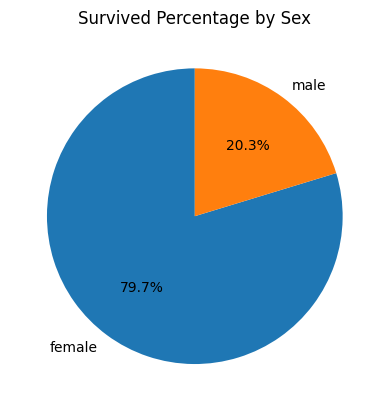

In [43]:
#pie chart for survived % grouped by sex
# Calculate survived counts by sex
survived_by_sex = df.groupby('sex')['survived'].mean() * 100  # % survived for each sex

# Prepare labels and sizes for pie chart
labels = survived_by_sex.index
sizes = survived_by_sex.values

plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)
plt.title('Survived Percentage by Sex')
plt.show()


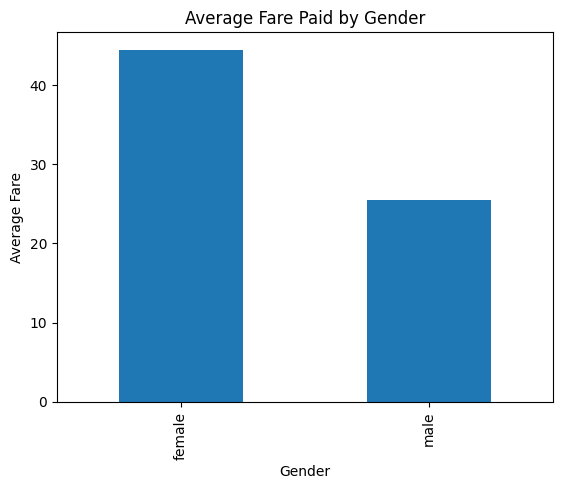

In [44]:
#bar plot (avg fare paid by each gender)
fare_by_sex = df.groupby('sex')['fare'].mean()
fare_by_sex.plot(kind='bar')
plt.title('Average Fare Paid by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Fare')
plt.show()

Text(0.5, 1.0, 'Age vs Fare by Gender and If Passenger was Alone or not')

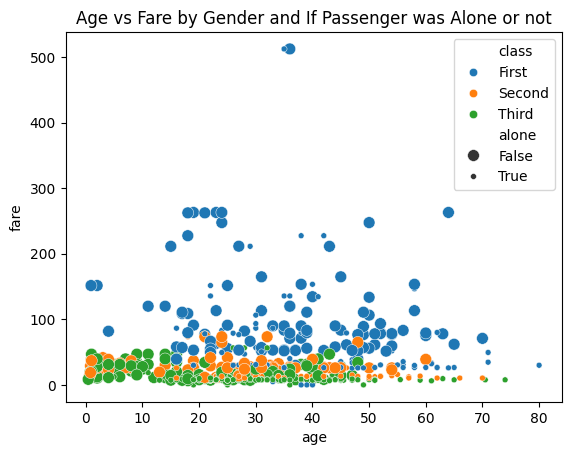

In [50]:
sns.scatterplot(data = df, x = 'age', y = 'fare', hue = 'class', size='alone')
plt.title('Age vs Fare by Gender and If Passenger was Alone or not')

scatterplot is expressive and effective
bar chart is effective and expressive
pie chart is effective but not expressive

scatterplot is most expressive
barchart is most effective
piechart ccan be misleading if too many categories or similar distributions



/tmp/ipython-input-1616227552.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_table = df.pivot_table(index='class', columns='sex', values='survived', aggfunc='mean')


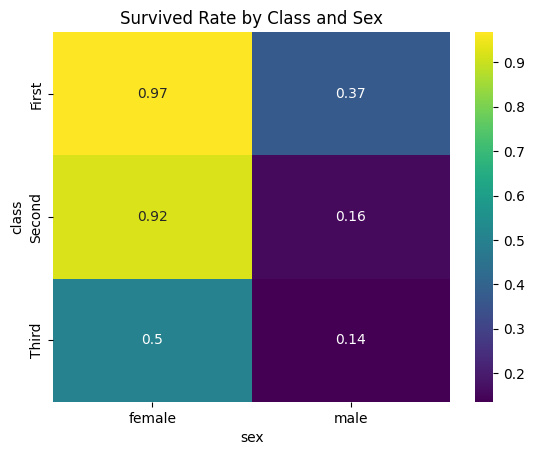

In [52]:
# Create a pivot table: survived rate by class and sex
pivot_table = df.pivot_table(index='class', columns='sex', values='survived', aggfunc='mean')

sns.heatmap(pivot_table, annot = True, cmap = 'viridis')
plt.title('Survived Rate by Class and Sex')
plt.show()

Text(0.5, 1.0, 'Heatmap with HSV colormap')

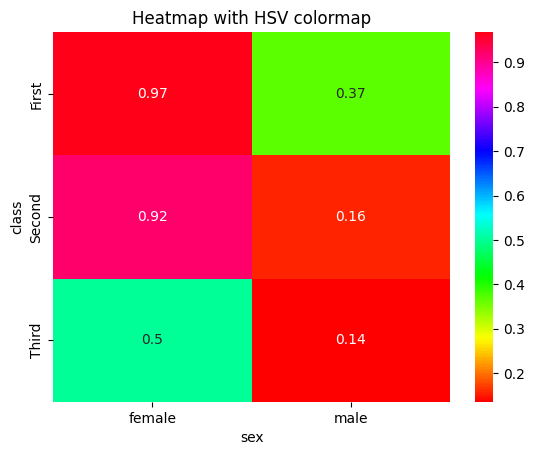

In [53]:
sns.heatmap(pivot_table, annot=True, cmap='hsv')
plt.title('Heatmap with HSV colormap')


RGB is more readable and interpretable. HSV has very similar and bright colors which dont look good, rgb is uniform

In [54]:
flights = sns.load_dataset('flights')
flights.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


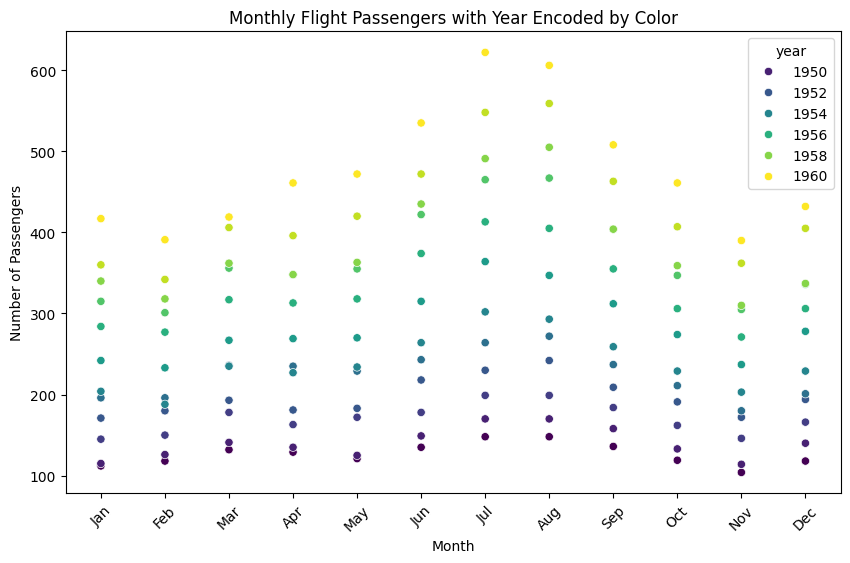

In [55]:
plt.figure(figsize=(10, 6))

# Scatter plot with color for year
sns.scatterplot(data=flights, x='month', y='passengers', hue='year', palette='viridis')

plt.title('Monthly Flight Passengers with Year Encoded by Color')
plt.xlabel('Month')
plt.ylabel('Number of Passengers')
plt.xticks(rotation=45)
plt.show()

/tmp/ipython-input-2907938371.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=flights, x='month', y='passengers', palette='coolwarm')


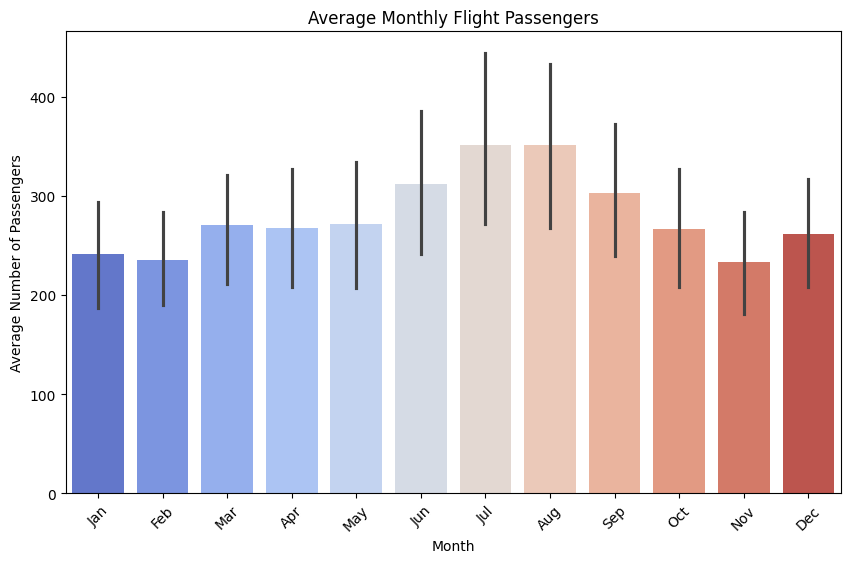

In [56]:
plt.figure(figsize=(10, 6))

# Bar plot showing average passengers by month
sns.barplot(data=flights, x='month', y='passengers', palette='coolwarm')

plt.title('Average Monthly Flight Passengers')
plt.xlabel('Month')
plt.ylabel('Average Number of Passengers')
plt.xticks(rotation=45)
plt.show()


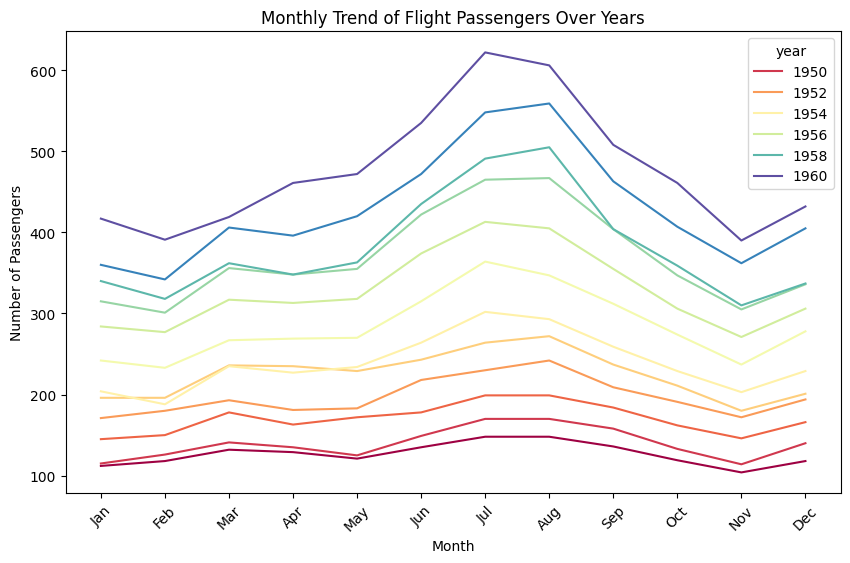

In [57]:
plt.figure(figsize=(10, 6))

# Line plot showing the trend of passengers over years
sns.lineplot(data=flights, x='month', y='passengers', hue='year', palette='Spectral')

plt.title('Monthly Trend of Flight Passengers Over Years')
plt.xlabel('Month')
plt.ylabel('Number of Passengers')
plt.xticks(rotation=45)
plt.show()


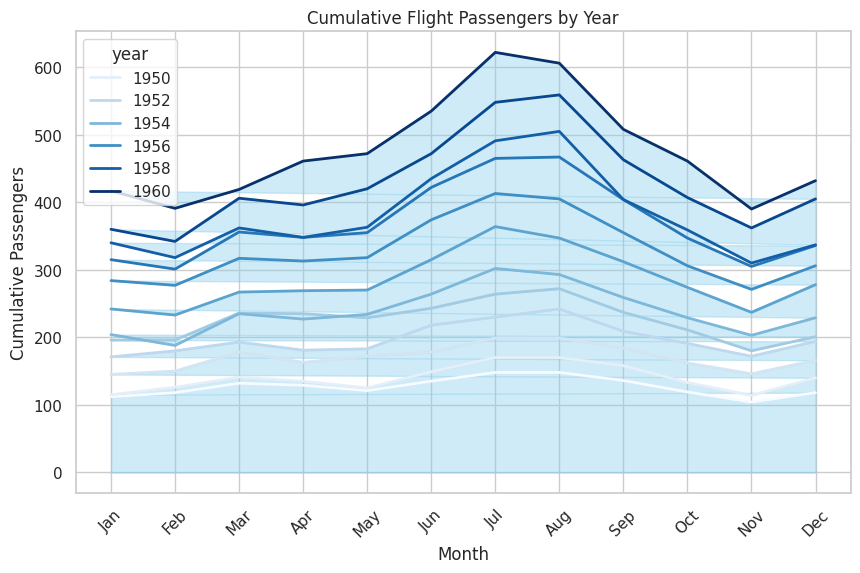

In [58]:
plt.figure(figsize=(10, 6))

# Area plot showing cumulative number of passengers by year
sns.set(style="whitegrid")
sns.lineplot(data=flights, x='month', y='passengers', hue='year', palette='Blues', lw=2)

plt.fill_between(flights['month'], flights['passengers'], color="skyblue", alpha=0.4)

plt.title('Cumulative Flight Passengers by Year')
plt.xlabel('Month')
plt.ylabel('Cumulative Passengers')
plt.xticks(rotation=45)
plt.show()